In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
# Add the project root directory to Python path
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

# Now you can import PitchExtractor
from modules.pitch_extractor import PitchExtractor

In [2]:
pitch_extractor = PitchExtractor()
pitch_extractor

[-2.9673258e-05 -3.6110661e-05 -3.8504204e-05 ... -3.0914794e-05
 -2.9738290e-05 -3.2249300e-05]


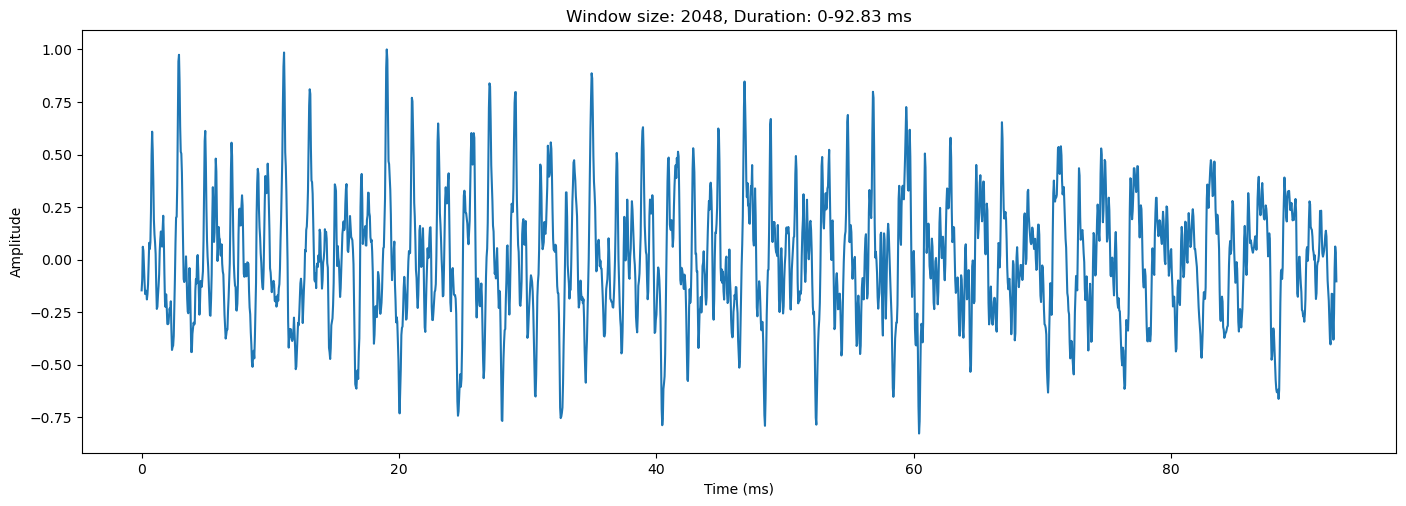

In [3]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

y, sr = librosa.load('./birds_of_feather.wav')
print(y)
windows_size = int(2048)
window_start = np.random.randint(0, len(y) - windows_size)
window_end = window_start + windows_size
window = y[window_start:window_end]
window = window / (np.max(np.abs(window)) + 1e-10) 

time_ms = np.arange(len(window)) * 1000 / sr

plt.figure(figsize=(14, 5))
plt.plot(time_ms, window)

plt.title(f'Window size: {windows_size}, Duration: 0-{time_ms[-1]:.2f} ms')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude')
plt.tight_layout(pad=0.5) # add padding to avoid overlap
plt.show()


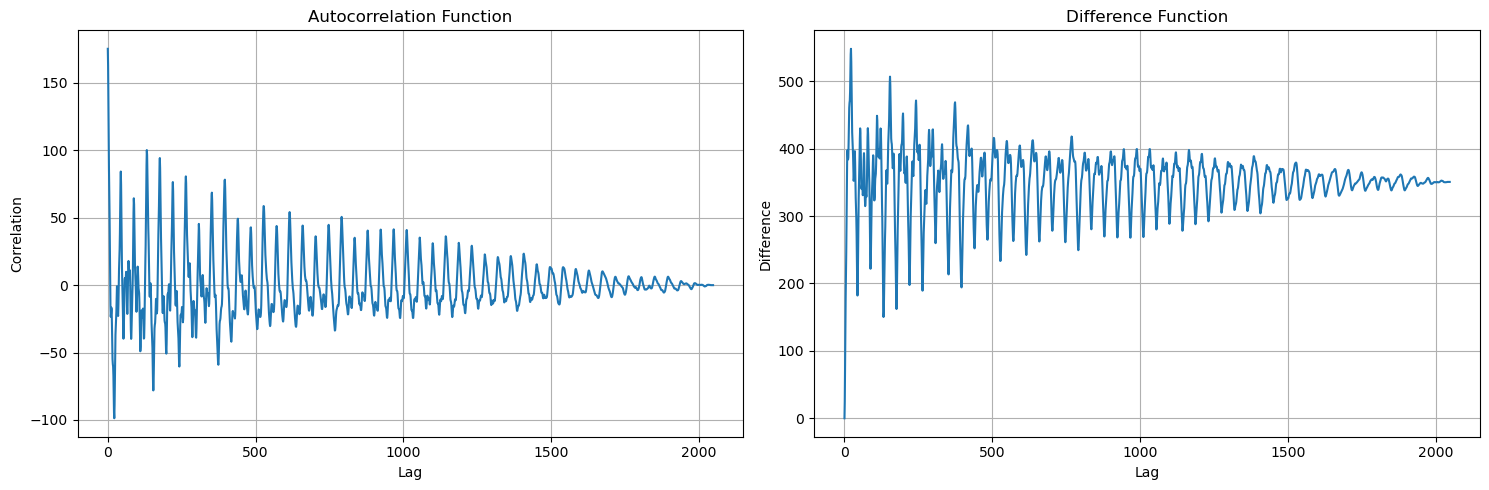

In [4]:
import matplotlib.pyplot as plt

# Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot autocorrelation function
acf = pitch_extractor._auto_correlation_function(window)
ax1.plot(acf)
ax1.set_title('Autocorrelation Function')
ax1.set_xlabel('Lag')
ax1.set_ylabel('Correlation')
ax1.grid(True)

# Plot difference function
diff_function = pitch_extractor._difference_function(window)
ax2.plot(diff_function)
ax2.set_title('Difference Function')
ax2.set_xlabel('Lag')
ax2.set_ylabel('Difference')
ax2.grid(True)

plt.tight_layout()
plt.show()

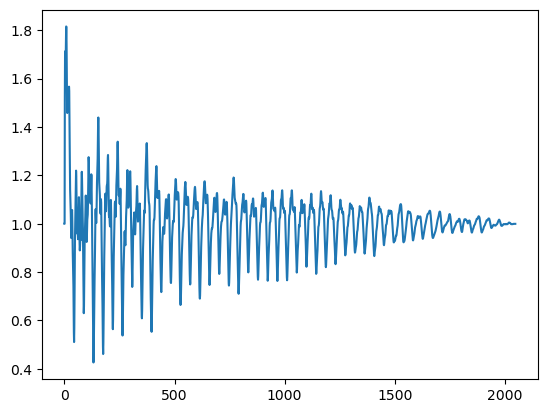

In [5]:
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff_function)
plt.plot(cmndf)

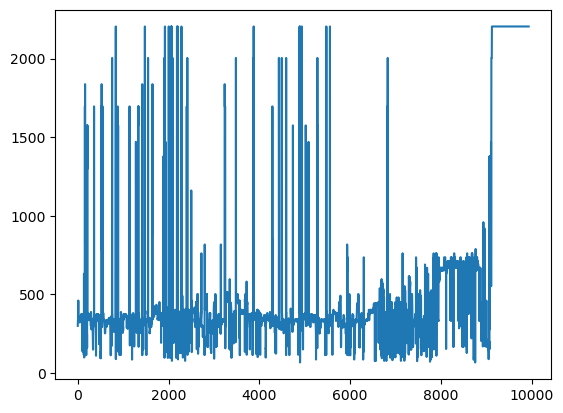

In [6]:
time, f0 = pitch_extractor.signal_pitch_extraction(y)
plt.plot(f0)

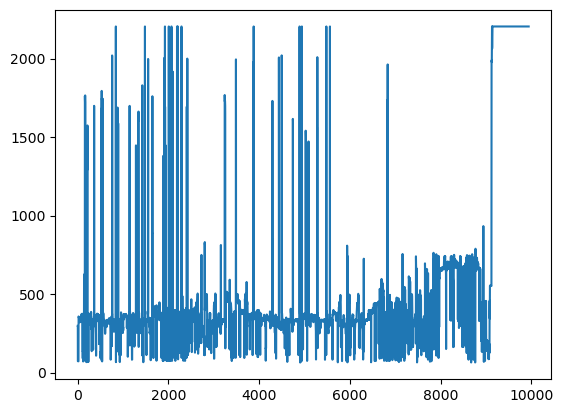

In [7]:
plt.plot(librosa.yin(y, fmin=65, fmax=2093, sr=sr))